In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import save_npz, load_npz

print("Libraries imported successfully!")


C:\Users\Icon\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Libraries imported successfully!


In [5]:

import os

folder_path = r"C:\Users\Icon\OneDrive\Desktop\Internship"

print("Folder exists:", os.path.exists(folder_path))

if os.path.exists(folder_path):
    print("\nFiles available in Internship folder:")
    print(os.listdir(folder_path))


Folder exists: True

Files available in Internship folder:
['ted_talks_eda_cleaned.csv', 'ted_talks_en.csv', 'ted_talks_preprocessed.xls']


In [9]:

import os

file_path = r"C:\Users\Icon\OneDrive\Desktop\Internship\ted_talks_preprocessed.xls"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    with open(file_path, "rb") as f:
        print("First bytes:", f.read(20))


File exists: True
First bytes: b'talk_id,title,speake'


In [10]:

import pandas as pd

file_path = r"C:\Users\Icon\OneDrive\Desktop\Internship\ted_talks_preprocessed.xls"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (4005, 20)


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript,combined_text
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre...",Averting the climate crisis ['alternative ener...
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac...","The best stats you've ever seen ['Africa', 'As..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun...","Simplicity sells ['computers', 'entertainment'..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...,"Greening the ghetto ['MacArthur grant', 'activ..."
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...,"Do schools kill creativity? ['children', 'crea..."


In [11]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import save_npz

print("All libraries imported successfully!")


All libraries imported successfully!


In [12]:

# Check available columns
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

# Select text columns available in the dataset
text_columns = [
    col for col in
    ["title", "topics", "description", "transcript"]
    if col in df.columns
]

print("Text columns selected:", text_columns)

if not text_columns:
    raise ValueError("No suitable text columns found in the dataset.")

for col in text_columns:
    df[col] = df[col].fillna("").astype(str)

df["combined_text"] = df[text_columns].agg(" ".join, axis=1)


df["combined_text"] = (
    df["combined_text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)


df = df[df["combined_text"].str.len() > 0].copy()
df.reset_index(drop=True, inplace=True)

print("Text preparation completed!")
print("Final dataset shape:", df.shape)

display(df[["combined_text"]].head())


Dataset shape: (4005, 20)
Columns: ['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript', 'combined_text']
Text columns selected: ['title', 'topics', 'description', 'transcript']
Text preparation completed!
Final dataset shape: (4005, 20)


,combined_text
0,Averting the climate crisis ['alternative ener...
1,"The best stats you've ever seen ['Africa', 'As..."
2,"Simplicity sells ['computers', 'entertainment'..."
3,"Greening the ghetto ['MacArthur grant', 'activ..."
4,"Do schools kill creativity? ['children', 'crea..."


In [13]:

tfidf_vectorizer = TfidfVectorizer(
    max_features=20000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    dtype=np.float32
)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    df["combined_text"]
)

print("TF-IDF vectorization completed!")
print("Number of talks:", tfidf_matrix.shape[0])
print("Number of features:", tfidf_matrix.shape[1])
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Matrix storage:", tfidf_matrix.nnz, "non-zero values")


TF-IDF vectorization completed!
Number of talks: 4005
Number of features: 20000
TF-IDF matrix shape: (4005, 20000)
Matrix storage: 1931509 non-zero values


In [14]:

joblib.dump(
    tfidf_vectorizer,
    "ted_tfidf_vectorizer.joblib"
)

from scipy.sparse import save_npz

save_npz(
    "ted_tfidf_matrix.npz",
    tfidf_matrix
)

df.to_csv(
    "ted_talks_features.csv",
    index=False
)

print("TF-IDF model saved!")
print("TF-IDF matrix saved!")
print("Feature dataset saved!")


TF-IDF model saved!
TF-IDF matrix saved!
Feature dataset saved!


In [15]:

similarity_matrix = cosine_similarity(
    tfidf_matrix,
    dense_output=False
)

save_npz(
    "ted_similarity_matrix.npz",
    similarity_matrix
)

print("Cosine similarity calculation completed!")
print("Similarity matrix shape:", similarity_matrix.shape)
print("Similarity matrix saved successfully!")


Cosine similarity calculation completed!
Similarity matrix shape: (4005, 4005)
Similarity matrix saved successfully!


In [16]:

def recommend_talks(talk_title, top_n=5):
    matches = df.index[
        df["title"].astype(str).str.contains(
            talk_title,
            case=False,
            regex=False,
            na=False
        )
    ].tolist()

    if not matches:
        print("Title not found. Please try another title.")
        return pd.DataFrame()

    talk_index = matches[0]

    scores = similarity_matrix.getrow(
        talk_index
    ).toarray().ravel()

    # Highest similarity first
    ranked_indices = np.argsort(scores)[::-1]

    # Remove the selected talk itself
    ranked_indices = [
        i for i in ranked_indices
        if i != talk_index
    ]

    top_indices = ranked_indices[:top_n]

    result_columns = [
        col for col in ["title", "speaker_1", "url"]
        if col in df.columns
    ]

    recommendations = df.iloc[top_indices][
        result_columns
    ].copy()

    recommendations["similarity_score"] = scores[top_indices]

    return recommendations.reset_index(drop=True)


In [17]:

# Display available TED Talk titles
display(df[["title"]].head(10))

# Test using the first talk's title
test_title = df.loc[0, "title"]

print("Selected TED Talk:", test_title)

recommendations = recommend_talks(
    test_title,
    top_n=5
)

display(recommendations)


,title
0,Averting the climate crisis
1,The best stats you've ever seen
2,Simplicity sells
3,Greening the ghetto
4,Do schools kill creativity?
5,Behind the design of Seattle's library
6,Letting go of God
7,Let's teach religion -- all religion -- in sch...
8,A life of purpose
9,My wish: A global day of film


Selected TED Talk: Averting the climate crisis


,title,speaker_1,url,similarity_score
0,New thinking on the climate crisis,Al Gore,https://www.ted.com/talks/al_gore_new_thinking...,0.205682
1,How we can turn the tide on climate,Chris Anderson,https://www.ted.com/talks/christiana_figueres_...,0.202657
2,The case for optimism on climate change,Al Gore,https://www.ted.com/talks/al_gore_the_case_for...,0.190649
3,What comes after An Inconvenient Truth?,Al Gore,https://www.ted.com/talks/al_gore_what_comes_a...,0.185593
4,A new way to remove CO2 from the atmosphere,Jennifer Wilcox,https://www.ted.com/talks/jennifer_wilcox_a_ne...,0.172413


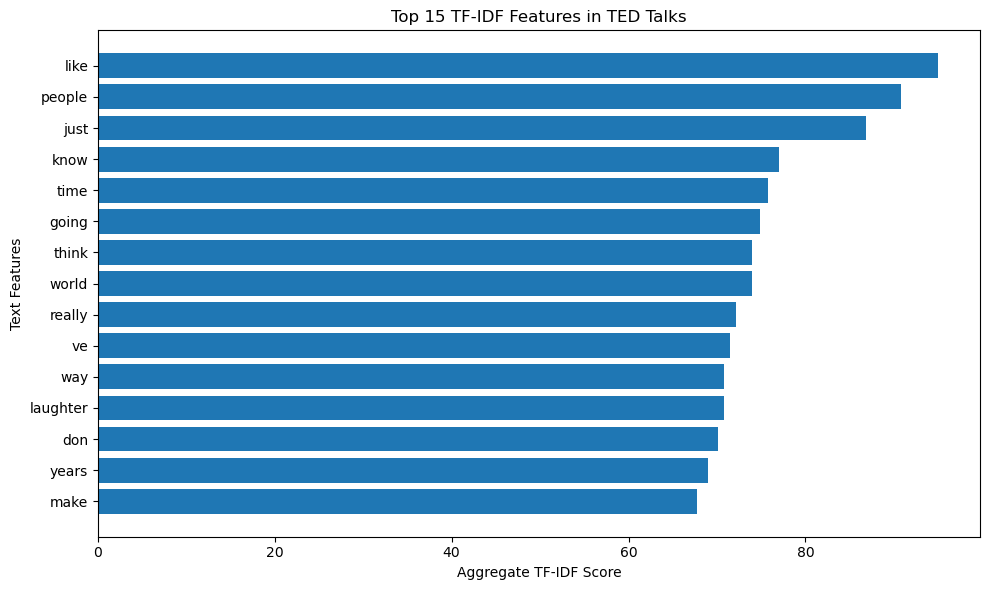

In [18]:

feature_names = tfidf_vectorizer.get_feature_names_out()

term_scores = np.asarray(
    tfidf_matrix.sum(axis=0)
).ravel()

top_n = 15
top_indices = np.argsort(term_scores)[-top_n:][::-1]

plt.figure(figsize=(10, 6))
plt.barh(
    feature_names[top_indices][::-1],
    term_scores[top_indices][::-1]
)

plt.xlabel("Aggregate TF-IDF Score")
plt.ylabel("Text Features")
plt.title("Top 15 TF-IDF Features in TED Talks")
plt.tight_layout()
plt.show()


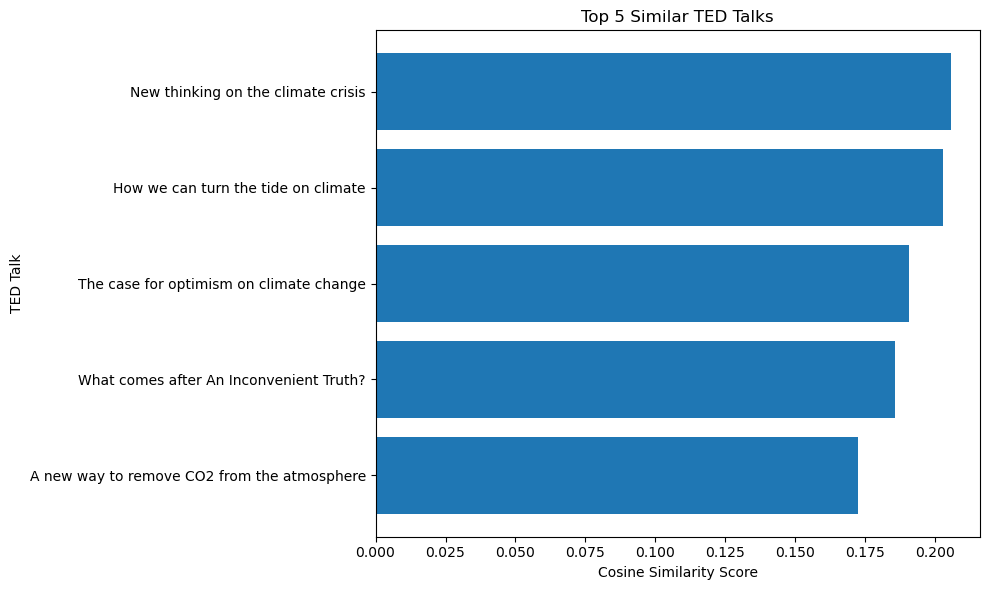

In [19]:

if not recommendations.empty:
    plot_data = recommendations.sort_values(
        "similarity_score",
        ascending=True
    )

    plt.figure(figsize=(10, 6))
    plt.barh(
        plot_data["title"],
        plot_data["similarity_score"]
    )

    plt.xlabel("Cosine Similarity Score")
    plt.ylabel("TED Talk")
    plt.title("Top 5 Similar TED Talks")
    plt.tight_layout()
    plt.show()
else:
    print("No recommendations available to visualize.")


In [20]:

interaction_file = "user_talk_interactions.csv"

if os.path.exists(interaction_file):
    interactions = pd.read_csv(interaction_file)

    required = {"user_id", "talk_id", "rating"}

    if required.issubset(interactions.columns):
        user_item_matrix = interactions.pivot_table(
            index="user_id",
            columns="talk_id",
            values="rating",
            aggfunc="mean"
        )

        user_item_sparse = user_item_matrix.fillna(0).astype(
            np.float32
        )

        from scipy.sparse import csr_matrix

        sparse_interactions = csr_matrix(
            user_item_sparse.to_numpy()
        )

        save_npz(
            "ted_user_item_matrix.npz",
            sparse_interactions
        )

        print("User-item interaction matrix saved!")
        print("Matrix shape:", sparse_interactions.shape)
    else:
        print("Required columns: user_id, talk_id, rating")
else:
    print("No interaction file found.")
    print("Collaborative filtering will be added when real interaction data is available.")


No interaction file found.
Collaborative filtering will be added when real interaction data is available.


In [21]:

output_files = [
    "ted_tfidf_vectorizer.joblib",
    "ted_tfidf_matrix.npz",
    "ted_talks_features.csv",
    "ted_similarity_matrix.npz"
]

print("=" * 45)
print("FEATURE ENGINEERING AND VECTORIZATION REPORT")
print("=" * 45)

print("Talks processed:", len(df))
print("Text columns used:", text_columns)
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Similarity matrix shape:", similarity_matrix.shape)

print("\nSaved files:")
for file in output_files:
    print(f"{file}: {'Yes' if os.path.exists(file) else 'No'}")

print("\nFeature engineering completed!")


FEATURE ENGINEERING AND VECTORIZATION REPORT
Talks processed: 4005
Text columns used: ['title', 'topics', 'description', 'transcript']
TF-IDF matrix shape: (4005, 20000)
Similarity matrix shape: (4005, 4005)

Saved files:
ted_tfidf_vectorizer.joblib: Yes
ted_tfidf_matrix.npz: Yes
ted_talks_features.csv: Yes
ted_similarity_matrix.npz: Yes

Feature engineering completed!
